In [16]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict  
from dotenv import load_dotenv
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.prompts import PromptTemplate

In [21]:
class LLmState(TypedDict):
    topic : str
    blog : str
    report : str

In [22]:
load_dotenv()
model = ChatGoogleGenerativeAI(
    model = "gemini-3.5-flash-lite"
)

In [23]:
def topic_to_description(state : LLmState) -> LLmState:
    topic = state['topic']
    prompt = f'Generate a detailed report on the topic - {topic}'
    report = model.invoke(prompt).content
    state['report'] = report
    return state


def description_to_blog(state : LLmState) -> LLmState:
    topic = state['topic']
    report = state['report']

    prompt = f'''Generate a creative and professional blog on the topic - {topic} \n
    with the help of the following report-\n
    {report}'''

    blog = model.invoke(prompt).content

    state['blog'] = blog
    return state



In [24]:
graph = StateGraph(LLmState)
#start -> topic to description -> description to  blog -> output
graph.add_node('topic_to_description', topic_to_description)
graph.add_node('description_to_blog', description_to_blog)

graph.add_edge(START, 'topic_to_description')
graph.add_edge('topic_to_description', 'description_to_blog')
graph.add_edge('description_to_blog', END)

workflow = graph.compile()

initial_state = {'topic' : 'langgraph'}

final_state = workflow.invoke(initial_state)
print(final_state)

{'topic': 'langgraph', 'blog': [{'type': 'text', 'text': '# Breaking the Loop: Why LangGraph is the Missing Link in Production-Grade AI Agents\n\nWe’ve all been there. You prompt an LLM to build a feature, write a script, or analyze a dataset. It does an impressive job on step one, stumbles on step two, and instead of course-correcting, it spirals into a hallucination loop or simply stops dead in its tracks. \n\nWhy? Because traditional AI workflows suffer from a severe architectural limitation: **they are designed to move in a straight line.**\n\nMost standard workflow engines rely on Directed Acyclic Graphs (DAGs)—pipelines that assume progress is strictly forward. But true intelligence isn\'t linear; it’s iterative. Real-world agents need to *reason, act, observe, fail, and try again*. \n\nEnter **LangGraph**. Developed by the creators of LangChain, LangGraph is an orchestration framework built specifically to solve the chaos of multi-step, autonomous AI. By treating agent workflows

[{'type': 'text', 'text': '# Comprehensive Technical Report: LangGraph\n\n## 1. Executive Summary\nAs Large Language Models (LLMs) transition from simple text-in/text-out interfaces to autonomous agents capable of complex reasoning and multi-step execution, managing application state and control flow has become the central engineering challenge. **LangGraph**, developed by LangChain, is an orchestration framework specifically designed to build robust, stateful, multi-actor applications with LLMs. \n\nUnlike traditional Directed Acyclic Graph (DAG) execution engines that assume a linear or strictly forward flow, LangGraph introduces support for **cycles**. This capability allows agents to reason, act, observe, and iterate dynamically—hallmarks of true autonomous behavior—while maintaining strict programmatic control over state transitions and error handling.\n\n---\n\n## 2. Motivation and Core Concepts\n\n### 2.1 The Limitation of DAGs in Agentic Workflows\nMost standard workflow engine

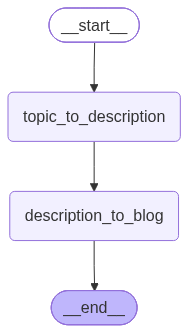

In [28]:
from  IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())